# IoTShield — 01: Keşifsel Veri Analizi (EDA) ve Veri Ön İşleme
**SE3513 · ASEADOS-SDN-IoT · 5 sınıf (Benign, Dos, DDoS, Bot, Prob)**

Bu notebook projeyi sıfırdan, daha önce yaşadığımız **"Bot / DDoS / Prob karışıyor"** sorununu göz önüne alarak kurar.
Her bölüm üç parçadan oluşur: *ne yapıyoruz → kod → ne bulduk / ne karar verdik*.

**Bu notebook'un vardığı ana sonuçlar (detayları aşağıda):**
1. Byte bilgisinin sıfır olması **saldırıya özgü değil**, bazı **kayıt oturumlarının hatalı ayrıştırılmasından** kaynaklanıyor. `Protocol == 0` olan 127 bin satırın 42.7 bini Benign, 16 bini Dos. Bu satırlarda IP adresleri de bozuk (`8.128.192.168` aslında `192.168.8.128`).
2. Her saldırı türü **tek bir kısa oturumda** kaydedilmiş (Bot 32 dk, DDoS 19 dk). Rastgele bölme, aynı saniyelerin parçalarını hem eğitime hem teste koyuyor. Bu yüzden **zaman bloklu bölme** kullanacağız.
3. Byte/header/flag özellikleri bozuk satırlarda hep 0 olduğu için model "byte = 0 ise saldırı" kısayolunu öğrenebiliyor. Mininet'te bu kısayol çöker. Bu yüzden **artefaktsız (zamanlama + paket sayısı) özellik seti** ana deney olacak.


In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
DATA_PATH = 'ASEADOS_SDN_IoT.csv'   # kendi yolunuza göre değiştirin
CLASS_ORDER = ['Benign', 'Dos', 'DDoS', 'Bot', 'Prob']

## 1. Veriyi yükleme ve ilk bakış

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.str.strip()
print(df.shape)
df.info(verbose=False)
df.head()

(457044, 84)
<class 'pandas.DataFrame'>
RangeIndex: 457044 entries, 0 to 457043
Columns: 84 entries, Flow ID to Label
dtypes: float64(45), int64(34), str(5)
memory usage: 332.0 MB


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Fwd Byts/b Avg,Fwd Pkts/b Avg,Fwd Blk Rate Avg,Bwd Byts/b Avg,Bwd Pkts/b Avg,Bwd Blk Rate Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Fwd Win Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,8.128.192.168-85.245.192.168-0-0-0,85.245.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:04 PM,3241760,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.616949,3241760.0,0.0,3241760.0,3241760.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.308474,0.308474,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot
1,8.128.192.168-31.125.192.168-0-0-0,31.125.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:08 PM,17649667,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.113317,17649667.0,0.0,17649667.0,17649667.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.056658,0.056658,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,17649667.0,0.0,17649667.0,17649667.0,Bot
2,8.128.192.168-82.28.192.168-0-0-0,82.28.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:07 PM,24923670,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.080245,24923670.0,0.0,24923670.0,24923670.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.040123,0.040123,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,24923670.0,0.0,24923670.0,24923670.0,Bot
3,8.128.192.168-76.22.192.168-0-0-0,76.22.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5399930,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.370375,5399930.0,0.0,5399930.0,5399930.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.185188,0.185188,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,5399930.0,0.0,5399930.0,5399930.0,Bot
4,8.128.192.168-72.128.192.168-0-0-0,72.128.192.168,0,8.128.192.168,0,0,12/03/2025 03:07:27 PM,5436008,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.367917,5436008.0,0.0,5436008.0,5436008.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.183959,0.183959,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,1,0,-1,-1,0,0,0.0,0.0,0.0,0.0,5436008.0,0.0,5436008.0,5436008.0,Bot


## 2. Sınıf dağılımı
Dengesizliği görmek ve metrik seçimimizi (macro F1) gerekçelendirmek için.

,adet,oran_%
Label,,
Benign,260797,57.06
Dos,127772,27.96
DDoS,51465,11.26
Bot,9090,1.99
Prob,7920,1.73


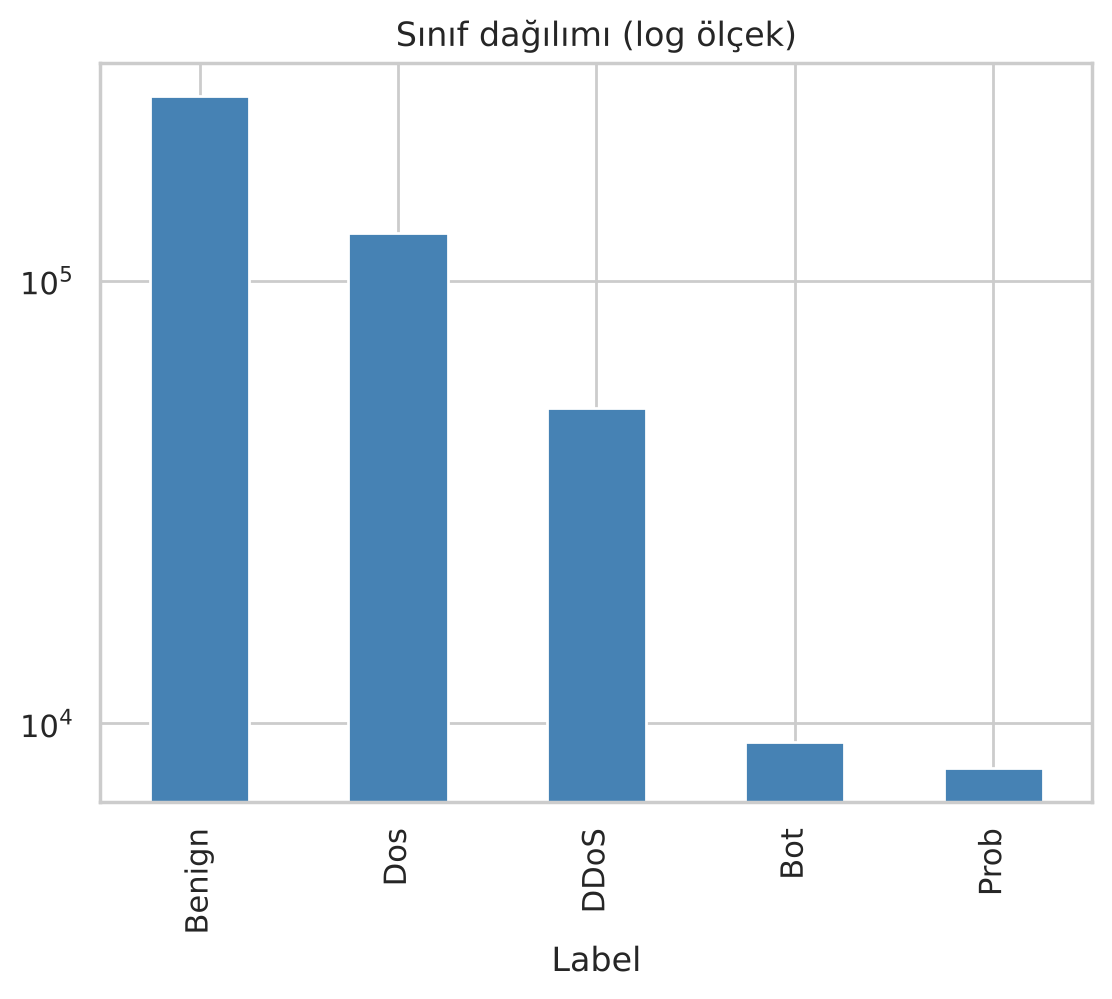

In [3]:
vc = df['Label'].value_counts().reindex(CLASS_ORDER)
display(pd.DataFrame({'adet': vc, 'oran_%': (vc / len(df) * 100).round(2)}))
ax = vc.plot.bar(color='steelblue'); ax.set_yscale('log'); ax.set_title('Sınıf dağılımı (log ölçek)'); plt.show()

**Bulgu:** Benign %57, Bot ve Prob ~%2. Accuracy yanıltıcı olur. Ana metrik **macro F1**, ayrıca sınıf bazında recall ve confusion matrix raporlanacak.

## 3. Veri kalitesi kontrolleri
Eksik / sonsuz / negatif değerler, sabit sütunlar, birebir aynı sütunlar, tekrar eden satırlar ve **aynı özellik değerleriyle farklı etiket taşıyan satırlar**.

In [4]:
ID_COLS   = ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp']
num_cols  = [c for c in df.columns if c not in ID_COLS + ['Label']]
X = df[num_cols]

print('NaN    :', X.isna().sum()[lambda s: s > 0].to_dict())
print('inf    :', np.isinf(X).sum()[lambda s: s > 0].to_dict())
print('negatif:', (X < 0).sum()[lambda s: s > 0].to_dict())

const_cols = [c for c in num_cols if X[c].nunique(dropna=False) <= 1]
print(f'\nSabit sütun ({len(const_cols)}):', const_cols)

# Birebir aynı içerikli sütunlar
seen, dup_cols = {}, []
for c in num_cols:
    h = pd.util.hash_pandas_object(X[c], index=False).sum()
    (dup_cols.append((c, seen[h])) if h in seen else seen.__setitem__(h, c))
print('\nBirebir aynı sütunlar:', [p for p in dup_cols if p[0] not in const_cols])

NaN    : {'Flow Byts/s': 66}
inf    : {'Flow Byts/s': 4, 'Flow Pkts/s': 70}
negatif: {'Flow Duration': 2, 'Flow Pkts/s': 2, 'Flow IAT Mean': 2, 'Flow IAT Max': 1, 'Flow IAT Min': 427, 'Fwd IAT Min': 10, 'Bwd IAT Tot': 1, 'Bwd IAT Mean': 1, 'Bwd IAT Max': 1, 'Bwd IAT Min': 11, 'Init Fwd Win Byts': 457044, 'Init Bwd Win Byts': 128878}



Sabit sütun (14): ['Fwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Init Fwd Win Byts', 'Fwd Seg Size Min']



Birebir aynı sütunlar: [('PSH Flag Cnt', 'Bwd PSH Flags'), ('Subflow Fwd Pkts', 'Tot Fwd Pkts'), ('Subflow Bwd Pkts', 'Tot Bwd Pkts')]


In [5]:
dup_mask = df.duplicated(subset=num_cols + ['Label'])
print('Tekrar eden satır (özellik+etiket):', dup_mask.sum())
display(df.loc[dup_mask, 'Label'].value_counts())

n_labels = df.groupby(num_cols, dropna=False)['Label'].transform('nunique')
print('Aynı özellik vektörü, farklı etiket (çelişkili) satır:', (n_labels > 1).sum())
display(df.loc[n_labels > 1, 'Label'].value_counts())

Tekrar eden satır (özellik+etiket): 29993


Label
Benign    27046
Dos        1265
DDoS       1195
Prob        354
Bot         133
Name: count, dtype: int64

Aynı özellik vektörü, farklı etiket (çelişkili) satır: 3763


Label
DDoS      1310
Dos        965
Benign     640
Prob       493
Bot        355
Name: count, dtype: int64

**Bulgu:**
- `Flow Byts/s` (66 NaN, 4 inf) ve `Flow Pkts/s` (70 inf): süresi 0 olan akışlardan geliyor. Bu değerler **0 ile doldurulacak**.
- Birkaç yüz satırda negatif IAT/süre var (saat kayması). **0'a kırpılacak.**
- 14 sabit sütun var (`Init Fwd Win Byts` hep −1, bulk/URG/CWE/ECE sütunları hep 0). **Atılacak.**
- `Subflow Fwd/Bwd Pkts` sütunları `Tot Fwd/Bwd Pkts` ile, `PSH Flag Cnt` de `Bwd PSH Flags` ile birebir aynı. **Biri atılacak.**
- ~30 bin tekrar eden satır var (çoğu Benign). **Bölmeden önce silinecek**, yoksa aynı satır hem train'e hem test'e düşer.
- 709 özellik vektörü birden fazla etiket taşıyor (~3.7 bin satır). Hiçbir model bunları ayıramaz. **Çelişkili gruplar atılacak**, raporda ayrıca belirtilecek.

## 4. ⭐ Asıl sorunun analizi: "byte = 0" kimde, neden?
Danışma raporundaki hipotez "Bot/DDoS/Prob'da byte bilgisi okunamamış" idi. Bunu sınıf bazında değil, **`Protocol == 0` (bozuk ayrıştırma) bayrağı** üzerinden inceliyoruz.

In [6]:
BYTE_COLS = ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Flow Byts/s', 'Pkt Len Max']
df['broken'] = df['Protocol'] == 0
df['bytes0'] = (df[BYTE_COLS] == 0).all(axis=1)

display(pd.crosstab(df['Label'], df['Protocol']).reindex(CLASS_ORDER))
display(pd.crosstab(df['Label'], df['broken'], margins=True).reindex(CLASS_ORDER + ['All']))
print('Bozuk satırlarda byte=0 oranı:', df.loc[df.broken, 'bytes0'].mean().round(3))

Protocol,0,6,17
Label,,,
Benign,42740,216512,1545
Dos,16075,111654,43
DDoS,51465,0,0
Bot,9090,0,0
Prob,7920,0,0


broken,False,True,All
Label,,,
Benign,218057,42740,260797
Dos,111697,16075,127772
DDoS,0,51465,51465
Bot,0,9090,9090
Prob,0,7920,7920
All,329754,127290,457044


Bozuk satırlarda byte=0 oranı: 0.999


In [7]:
# Bozuk satırlarda hangi özellikler hep 0 / -1? Bunlar "bozuk mu?" bilgisini sızdıran artefakt sütunları.
num_ok = [c for c in num_cols if c not in const_cols]
art = pd.DataFrame({
    'bozuk_satırda_<=0_%':  (df.loc[df.broken, num_ok] <= 0).mean() * 100,
    'normal_satırda_<=0_%': (df.loc[~df.broken, num_ok] <= 0).mean() * 100}).round(1)
ARTIFACT_COLS = art.index[art['bozuk_satırda_<=0_%'] >= 99].tolist()   # %99+: Flow Byts/s gibi neredeyse hep 0 olanlar da dahil
TIMING_COLS   = [c for c in num_ok if c not in ARTIFACT_COLS]
print(f'Bozuk satırlarda hep 0 olan ({len(ARTIFACT_COLS)}):', ARTIFACT_COLS)
print(f'\nBozuk satırlarda da değişen ({len(TIMING_COLS)}):', TIMING_COLS)

Bozuk satırlarda hep 0 olan (36): ['TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd PSH Flags', 'Fwd Header Len', 'Bwd Header Len', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Subflow Fwd Byts', 'Subflow Bwd Byts', 'Init Bwd Win Byts', 'Fwd Act Data Pkts']

Bozuk satırlarda da değişen (26): ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Down/Up Ratio', 'Subflow Fwd Pkts', 'Subflow Bwd Pkts', 'Active M

In [8]:
# Bozuk satırlarda IP adresleri: 16-bit kelimeleri yer değiştirmiş görünüyor (8.128.192.168 -> 192.168.8.128)
swapped = df['Dst IP'].astype(str).str.match(r'^\d+\.\d+\.192\.168$')
display(pd.crosstab(df['Label'], swapped).reindex(CLASS_ORDER))
for lab in CLASS_ORDER:
    s = df[df.Label == lab]
    print(f"{lab:7s} benzersiz src={s['Src IP'].nunique():6d} dst={s['Dst IP'].nunique():6d} | en sık src: {s['Src IP'].value_counts().head(3).to_dict()}")

Dst IP,False,True
Label,,
Benign,246067,14730
Dos,111809,15963
DDoS,6831,44634
Bot,2,9088
Prob,7920,0


Benign  benzersiz src= 14306 dst= 11842 | en sık src: {'192.168.4.9': 44555, '192.168.40.152': 20833, '192.168.40.153': 20737}
Dos     benzersiz src= 14349 dst=    13 | en sık src: {'200.175.2.130': 108267, '192.168.4.17': 3193, '192.168.40.150': 137}
DDoS    benzersiz src= 32952 dst=  6673 | en sık src: {'44.207.103.122': 2759, '220.166.50.247': 1481, '184.39.235.66': 1462}
Bot     benzersiz src=  8651 dst=     3 | en sık src: {'39.124.192.168': 3, '111.6.192.168': 3, '98.74.192.168': 3}
Prob    benzersiz src=     8 dst=  5623 | en sık src: {'0.12.41.142': 3996, '0.12.41.223': 3436, '184.39.235.66': 226}


**Bulgu (en önemli kısım):**
- `Protocol == 0` olan **127.290 satırın 42.740'ı Benign, 16.075'i Dos.** Yani "byte = 0" Bot/DDoS/Prob'a özgü değil. Bu, **bazı kayıt oturumlarının CICFlowMeter tarafından yanlış ayrıştırılmasının** sonucu.
- Bu satırlarda protokol, port, byte, header uzunluğu, flag ve TCP pencere bilgisi **hep 0 / −1**. Ellerinde yalnızca **zamanlama ve paket sayısı** kalıyor (~30 özellik).
- IP adresleri de bozuk: `8.128.192.168` gerçekte `192.168.8.128`. Bu adresin 16-bit yarıları yer değiştirmiş. Prob'da kaynak IP'ler `0.12.41.142` gibi anlamsız. Bot'ta 9.090 akış 8.651 farklı "kaynaktan" geliyor gibi görünüyor, bu da gürültü.
  Bu, paket başlığının **2 byte kaydırılarak okunduğuna** işaret ediyor (örneğin Linux "cooked capture" (SLL, 16 byte) kaydının Ethernet (14 byte) gibi okunması). Bu bir **hipotez**. PCAP'e bakarak doğrulanabilir.
- **Sonuç 1:** IP'lerle "bu hedefe kaç kaynak bağlandı" gibi bağlantılar arası özellik üretmek (danışma raporundaki B seçeneği) bu satırlarda **güvenilir değil**, çünkü IP alanı bozuk.
- **Sonuç 2:** Model "byte = 0 → Bot/DDoS/Prob" kuralını öğrenirse Mininet'te (byte dolu) çöker. Bu yüzden ana deneyde `ARTIFACT_COLS` modelden çıkarılacak.

## 5. ⭐ Zaman analizi: her saldırı ne zaman kaydedilmiş?
Bölme stratejisini belirleyen bölüm.

In [9]:
df['ts'] = pd.to_datetime(df['Timestamp'], format='%d/%m/%Y %I:%M:%S %p')
g = df.groupby('Label')['ts'].agg(['min', 'max', 'count']).reindex(CLASS_ORDER)
g['süre'] = g['max'] - g['min']; display(g)
display(pd.crosstab(df['ts'].dt.date, df['Label'])[CLASS_ORDER])

,min,max,count,süre
Label,,,,
Benign,2025-03-10 21:24:07,2025-03-24 12:23:14,260797,13 days 14:59:07
Dos,2023-11-22 02:24:11,2025-03-24 16:34:07,127772,488 days 14:09:56
DDoS,2025-03-10 15:47:43,2025-03-10 16:06:20,51465,0 days 00:18:37
Bot,2025-03-12 14:38:51,2025-03-12 15:11:08,9090,0 days 00:32:17
Prob,2025-02-10 16:45:56,2025-03-10 20:32:21,7920,28 days 03:46:25


Label,Benign,Dos,DDoS,Bot,Prob
ts,,,,,
2023-11-22,0,20711,0,0,0
2025-02-10,0,0,0,0,7489
2025-03-10,11417,0,51465,0,431
2025-03-12,16156,0,0,9090,0
2025-03-14,40468,0,0,0,0
2025-03-18,105764,0,0,0,0
2025-03-24,86992,107061,0,0,0


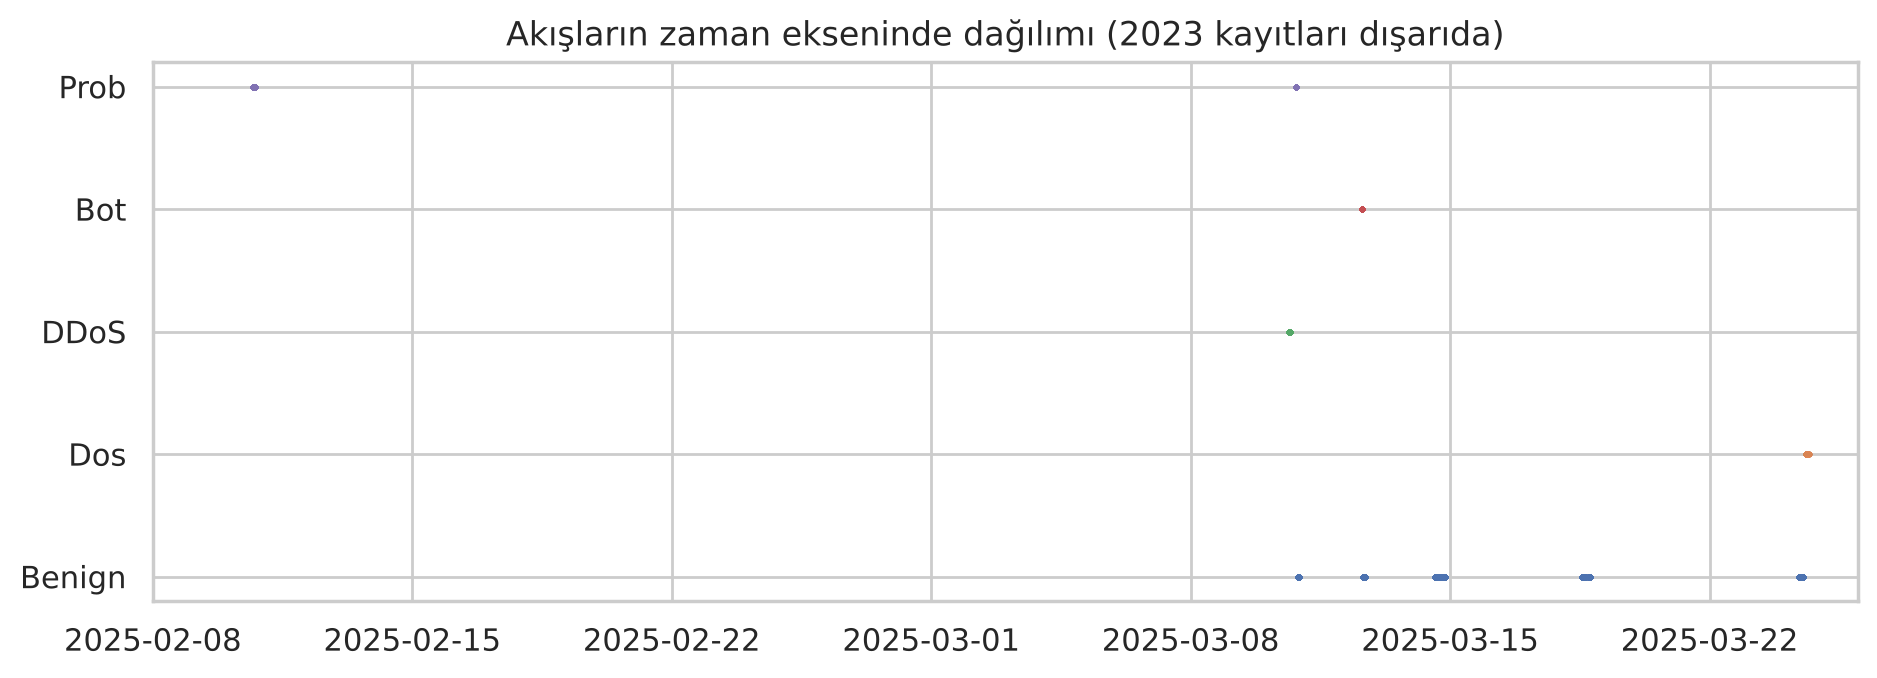

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, lab in enumerate(CLASS_ORDER):
    t = df.loc[df.Label == lab, 'ts']
    ax.scatter(t, np.full(len(t), i), s=1, alpha=.2)
ax.set_yticks(range(5), CLASS_ORDER); ax.set_xlim(pd.Timestamp('2025-02-08'), pd.Timestamp('2025-03-26'))
ax.set_title('Akışların zaman ekseninde dağılımı (2023 kayıtları dışarıda)'); plt.show()

**Bulgu:**
- Bot'un tamamı **12 Mart 14:38–15:11** (32 dk), DDoS'un tamamı **10 Mart 15:47–16:06** (19 dk) arasında kaydedilmiş.
- ~20.7 bin Dos satırı **2023-11-22** tarihli, büyük ihtimalle cihaz saati yanlış. Veri olarak tutuluyor, yalnızca not ediliyor.
- `Timestamp` doğrudan kullanılırsa model "saat 14:40 ise Bot" öğrenir. **Timestamp kesinlikle özellik olmayacak.**
- Rastgele %80/%20 bölmede aynı dakikanın komşu akışları hem train'de hem test'te olur. Model davranışı değil **o oturumu** öğrenir ve skor şişer.
- Saf zaman bölmesi (ilk %80 / son %20) da olmaz, çünkü her sınıf tek oturum. **Çözüm: dakika bloklarıyla, sınıf içinde serpiştirilmiş bölme.** Her sınıfın her 5. dakikası test'e gider. Komşu akışlar aynı tarafta kalır.

## 6. Bozuk satırlarda sınıflar zamanlama özellikleriyle ayrışıyor mu?

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Flow Pkts/s,Flow IAT Mean,Idle Mean
Label,,,,,,
Benign,64873209.5,1.0,1.0,0.1,21996594.9,25812558.8
Dos,46964482.0,1.0,1.0,0.0,39358024.5,41741425.0
DDoS,26775764.0,1.0,1.0,0.1,23429169.0,24442021.0
Bot,14213919.5,1.0,1.0,0.1,13099496.0,13486968.2
Prob,13670834.5,2.0,1.0,0.4,3822379.5,8196347.0


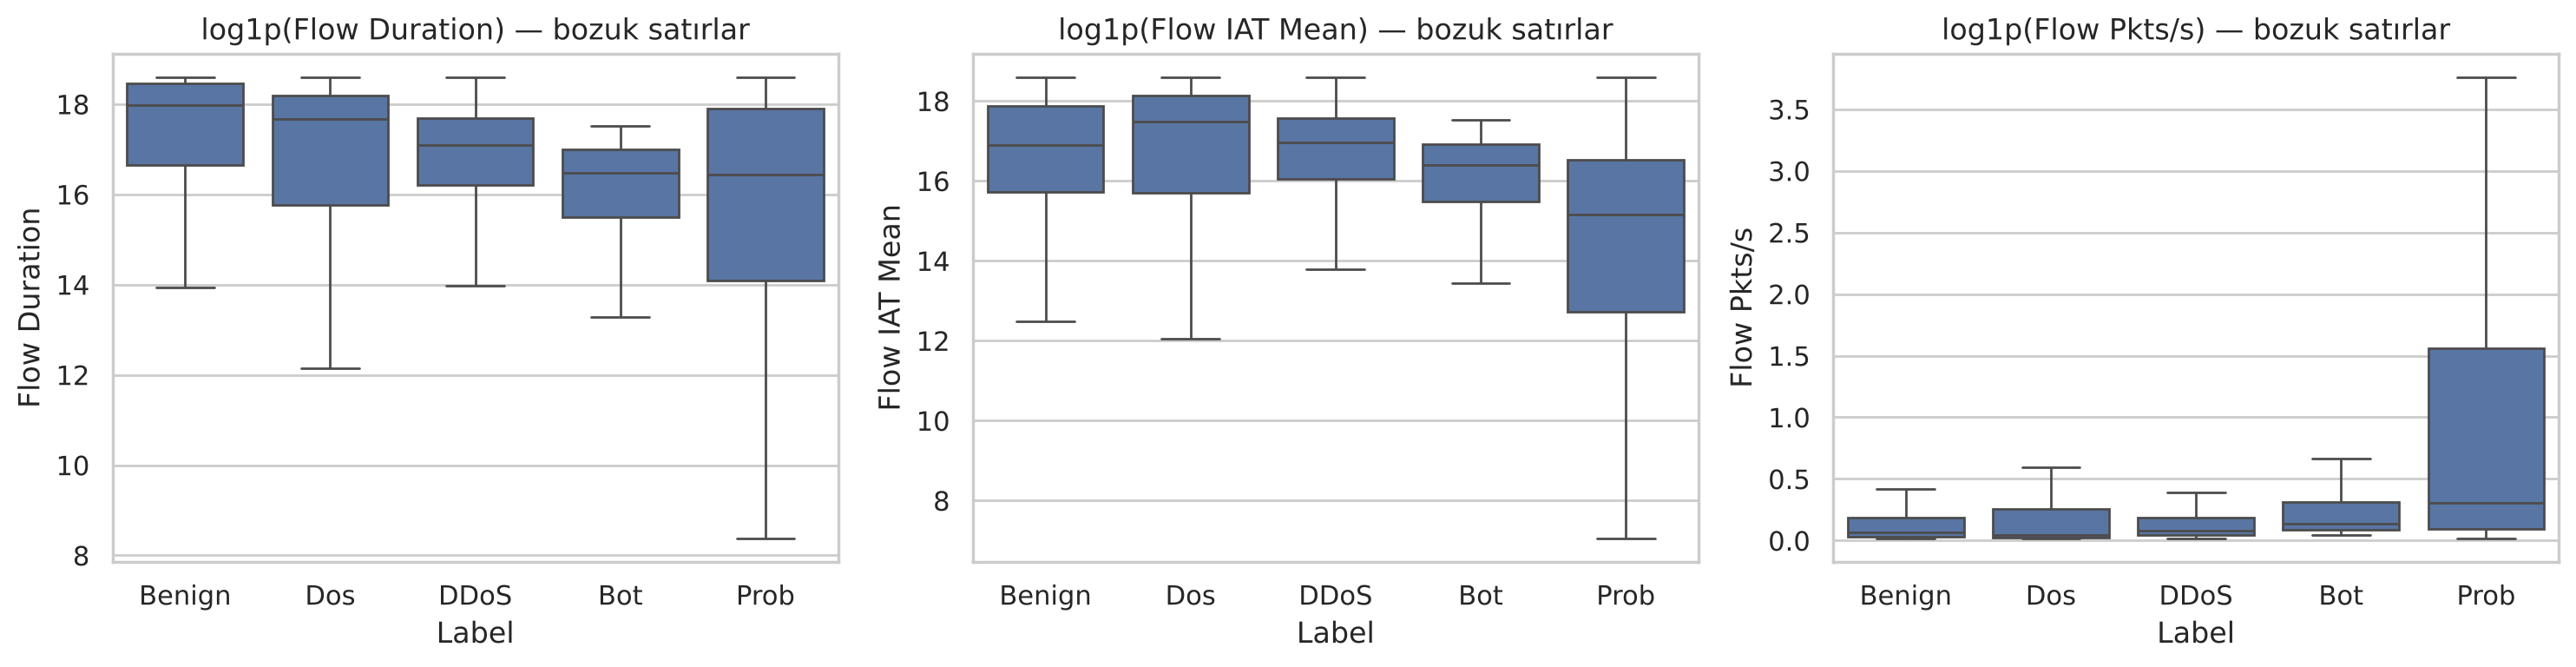

In [11]:
B = df[df.broken]
key = ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Mean', 'Idle Mean']
display(B.groupby('Label')[key].median().reindex(CLASS_ORDER).round(1))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['Flow Duration', 'Flow IAT Mean', 'Flow Pkts/s']):
    sns.boxplot(data=B, x='Label', y=np.log1p(B[c].clip(lower=0)), order=CLASS_ORDER, ax=ax, showfliers=False)
    ax.set_title(f'log1p({c}) — bozuk satırlar')
plt.tight_layout(); plt.show()

**Bulgu:** Bozuk satırların çoğu **1 ileri + 1 geri paketlik** ve uzun süreli "akışlar". Sınıflar arasındaki farklar (süre, IAT) gerçek ama dağılımlar büyük ölçüde örtüşüyor. Bot/DDoS/Prob karışıklığının asıl nedeni bu: **satır başına bilgi az**. Model değiştirmek bunu çözmez.

## 7. Korelasyon (artefaktsız özellikler)

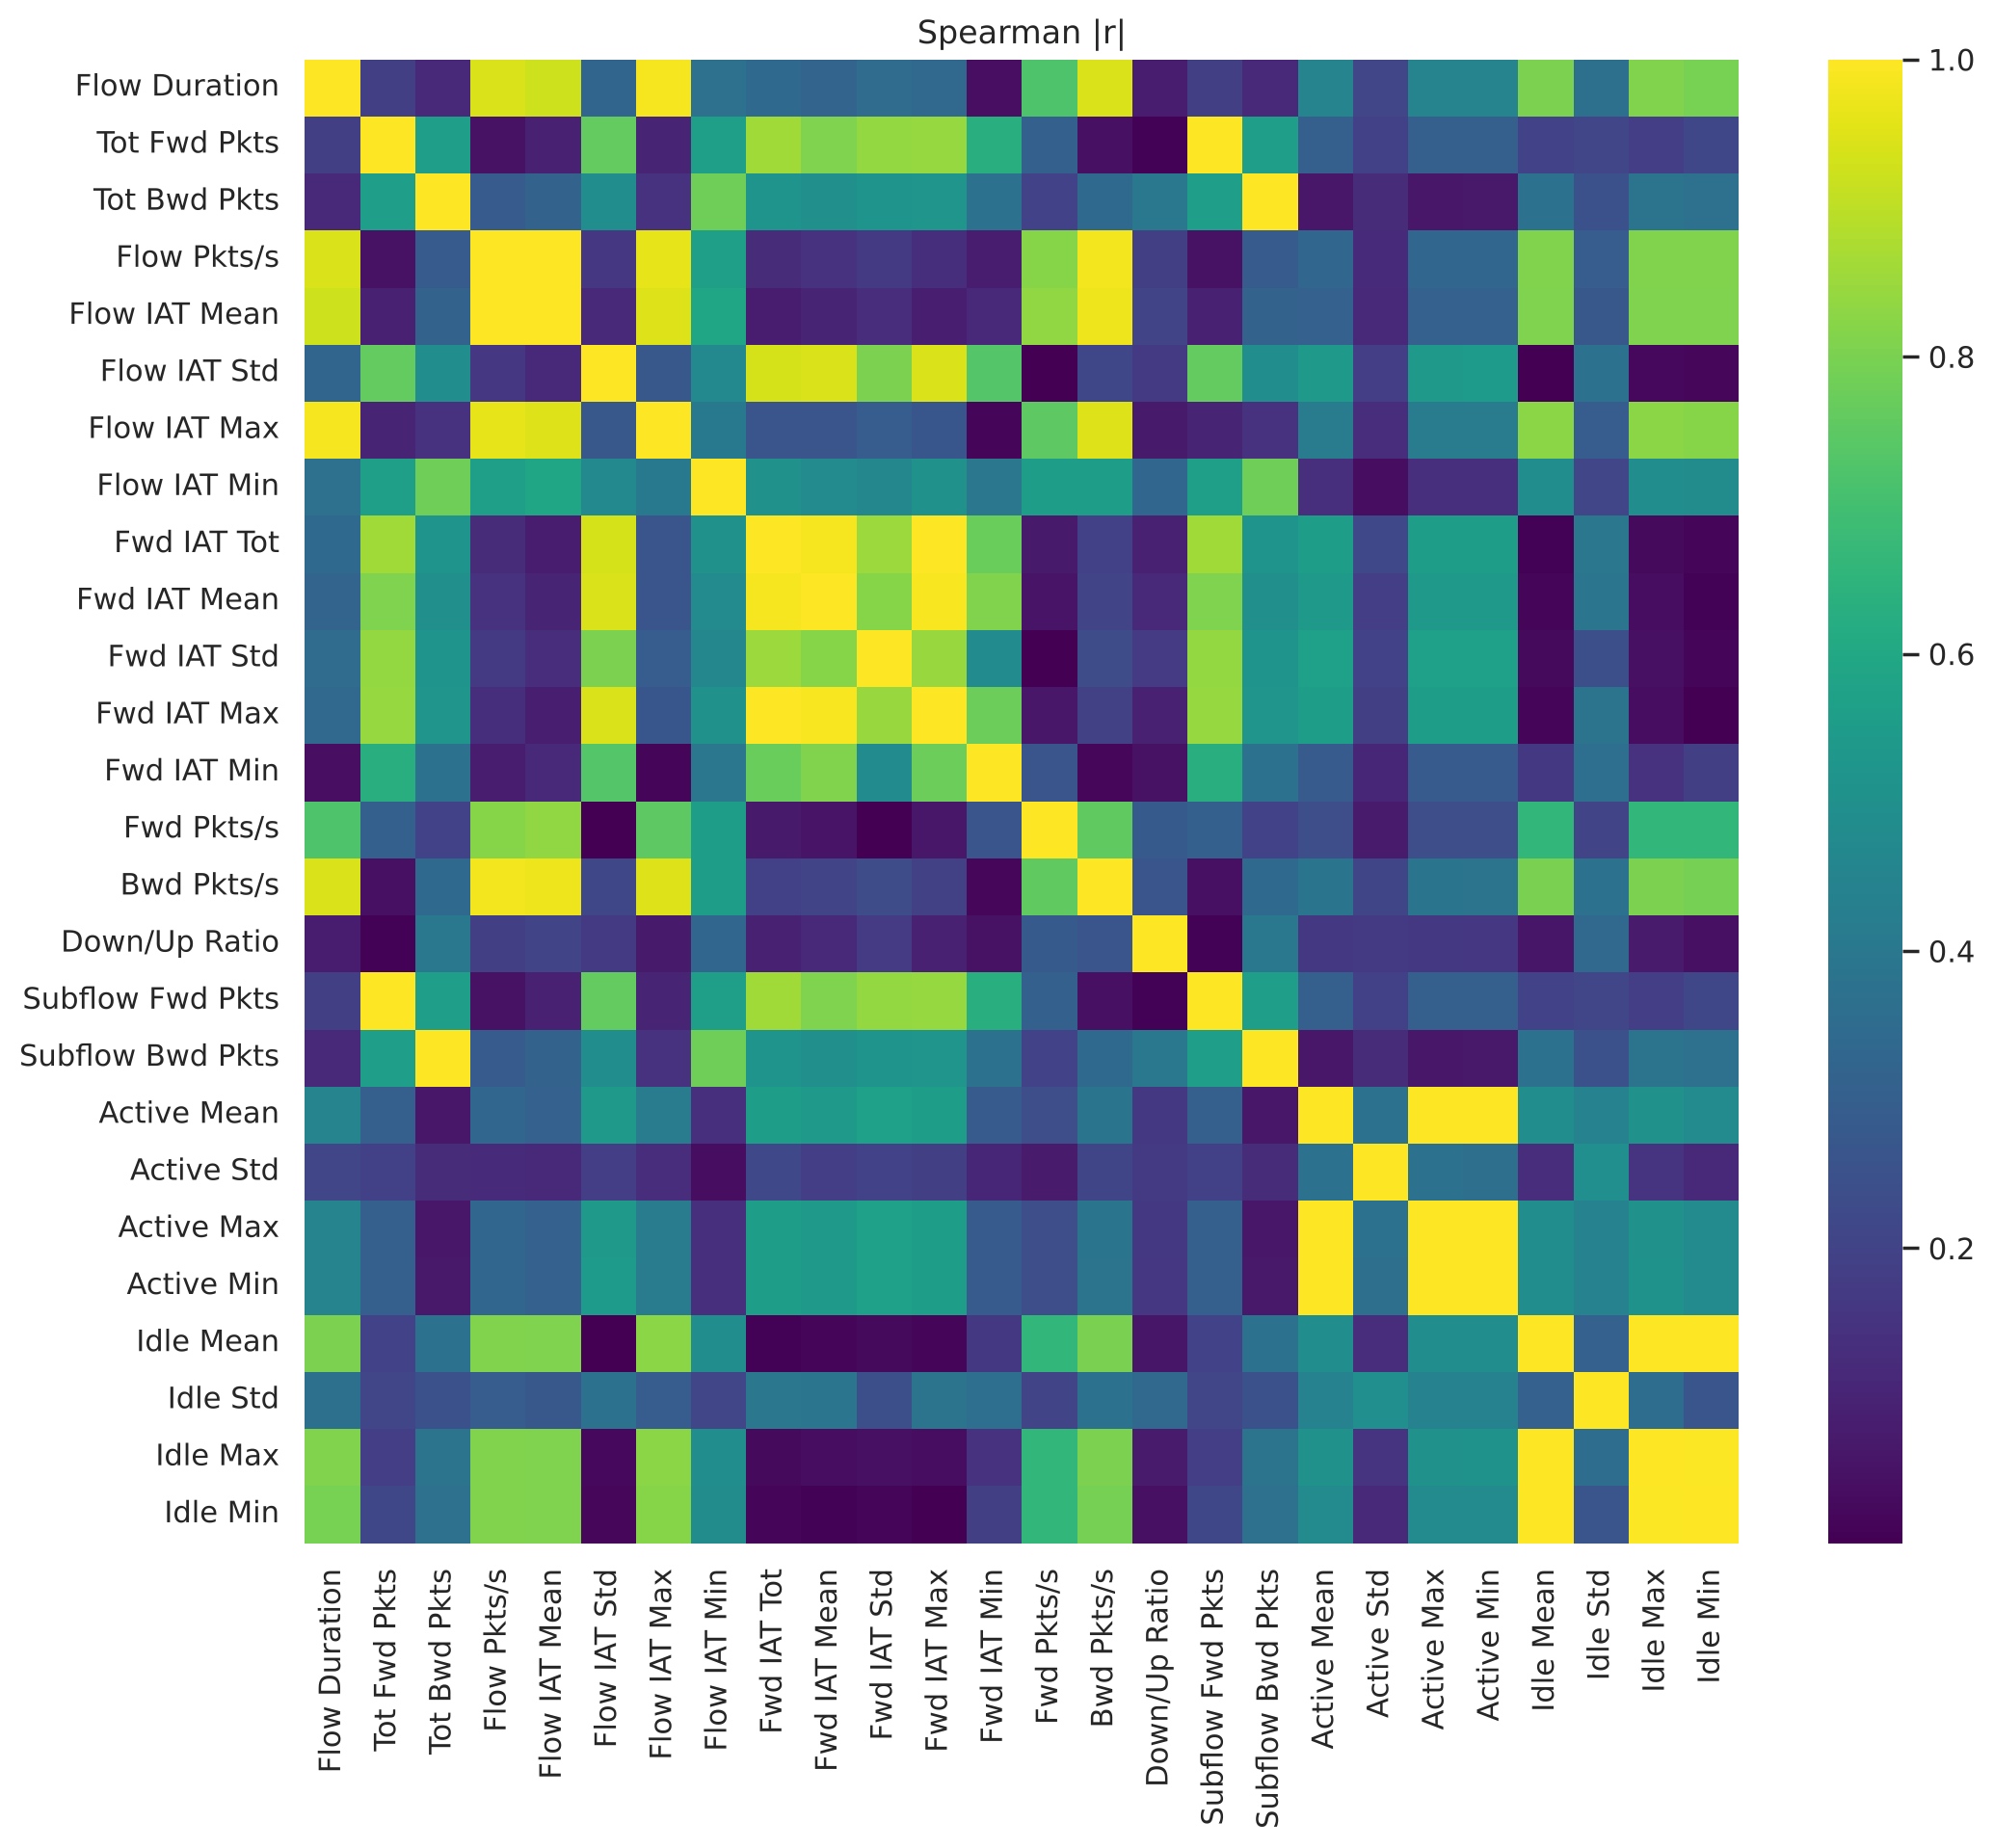

|r| > 0.95 çiftleri:
Tot Fwd Pkts   Subflow Fwd Pkts    1.000
Tot Bwd Pkts   Subflow Bwd Pkts    1.000
Active Mean    Active Max          1.000
               Active Min          1.000
Active Max     Active Min          1.000
Idle Mean      Idle Max            0.998
               Idle Min            0.998
Flow Pkts/s    Flow IAT Mean       0.997
Fwd IAT Tot    Fwd IAT Max         0.996
Idle Max       Idle Min            0.993
Fwd IAT Mean   Fwd IAT Max         0.990
Flow Duration  Flow IAT Max        0.986
Fwd IAT Tot    Fwd IAT Mean        0.984
Flow Pkts/s    Bwd Pkts/s          0.982
Flow IAT Mean  Bwd Pkts/s          0.976
Flow Pkts/s    Flow IAT Max        0.963
dtype: float64


In [12]:
corr = df[TIMING_COLS].corr(method='spearman').abs()
plt.figure(figsize=(12, 10)); sns.heatmap(corr, cmap='viridis', xticklabels=True, yticklabels=True); plt.title('Spearman |r|'); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
print('|r| > 0.95 çiftleri:'); print(upper.stack()[lambda s: s > .95].sort_values(ascending=False).round(3))

> Korelasyon budaması **yalnızca train verisi** üzerinde yapılır (8. bölümde). Burada sadece görmek için bakıyoruz.

## 8. Veri ön işleme (sıralama önemli!)
1. ID / zaman / IP / port / Protocol sütunlarını at
2. inf → NaN → 0, negatifleri 0'a kırp
3. Sabit ve birebir aynı sütunları at
4. Tekrar eden satırları sil, çelişkili grupları at
5. **Zaman bloklu split** (bölmeden önce hiçbir şey fit edilmez)
6. Train üzerinde korelasyon budaması
7. İki özellik seti: **F_timing** (artefaktsız, ana deney) ve **F_full** (karşılaştırma için)
8. Ölçekleme sadece LR için, pipeline içinde, train'e fit edilerek

In [13]:
clean = df.copy()
clean[num_cols] = clean[num_cols].replace([np.inf, -np.inf], np.nan).fillna(0).clip(lower=0)

drop_dupcols = ['Subflow Fwd Pkts', 'Subflow Bwd Pkts', 'PSH Flag Cnt']
FEATS = [c for c in num_cols if c not in const_cols + drop_dupcols]

before = len(clean)
clean = clean.drop_duplicates(subset=FEATS + ['Label'])
conflict = clean.groupby(FEATS)['Label'].transform('nunique') > 1
clean = clean[~conflict].reset_index(drop=True)
print(f'{before} -> {len(clean)} satır  (tekrar + çelişkili atıldı)')
display(clean['Label'].value_counts().reindex(CLASS_ORDER))

457044 -> 425406 satır  (tekrar + çelişkili atıldı)


Label
Benign    233389
Dos       126038
DDoS       49910
Bot         8689
Prob        7380
Name: count, dtype: int64

In [14]:
# Zaman bloklu, sınıf içinde serpiştirilmiş bölme: her sınıfın her 5. dakikası test
clean['minute'] = clean['ts'].astype('datetime64[s]').astype('int64') // 60
clean['blk_rank'] = clean.groupby('Label')['minute'].rank(method='dense').astype(int)
is_test = (clean['blk_rank'] % 5 == 0)
clean['group'] = clean['Label'] + '_' + clean['minute'].astype(str)   # CV için grup (StratifiedGroupKFold)

train, test = clean[~is_test].copy(), clean[is_test].copy()
print('train', train.shape, ' test', test.shape)
display(pd.concat([train.Label.value_counts(normalize=True), test.Label.value_counts(normalize=True)],
                  axis=1, keys=['train', 'test']).reindex(CLASS_ORDER).round(3))

train (334266, 90)  test (91140, 90)


,train,test
Label,,
Benign,0.564,0.492
Dos,0.281,0.352
DDoS,0.115,0.127
Bot,0.019,0.024
Prob,0.020,0.006


In [15]:
def prune_corr(frame, cols, thr=0.95):
    c = frame[cols].corr(method='spearman').abs()
    up = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
    return [x for x in cols if not (up[x] > thr).any()]

F_TIMING = prune_corr(train, [c for c in TIMING_COLS if c in FEATS])
F_FULL   = prune_corr(train, FEATS)
print(f'F_timing ({len(F_TIMING)}):', F_TIMING)
print(f'\nF_full   ({len(F_FULL)}):', F_FULL)

F_timing (15): ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Std', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Std', 'Fwd IAT Min', 'Fwd Pkts/s', 'Down/Up Ratio', 'Active Mean', 'Active Std', 'Idle Mean', 'Idle Std']

F_full   (33): ['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Min', 'Bwd Pkt Len Min', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Std', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Std', 'Bwd IAT Min', 'Bwd PSH Flags', 'Fwd Header Len', 'Fwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'ACK Flag Cnt', 'Down/Up Ratio', 'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Active Mean', 'Active Std', 'Idle Mean', 'Idle Std']


**Neden iki set?**
- **F_timing** (ana deney): Bozuk ve sağlam satırlarda, Mininet'te de aynı anlamı taşıyan özellikler. Model "byte = 0" kısayolunu öğrenemez.
- **F_full**: Literatürle kıyas için. Raporda "artefakt özellikleri çıkarınca ne kaybettik" sorusunu cevaplar.

## 9. Sızıntı kontrolü: rastgele bölme vs. zaman bloklu bölme
Aynı model, iki farklı bölme. Aradaki fark, rastgele bölmenin skoru ne kadar şişirdiğini gösterir. Raporda bir bulgu olarak kullanılacak.

,macroF1,Benign,Dos,DDoS,Bot,Prob
deney,,,,,,
F_full | rastgele,0.682,0.93,0.91,0.69,0.25,0.54
F_full | zaman bloklu,0.606,0.92,0.88,0.72,0.08,0.52
F_timing | rastgele,0.669,0.92,0.89,0.66,0.26,0.51
F_timing | zaman bloklu,0.582,0.91,0.87,0.67,0.09,0.44


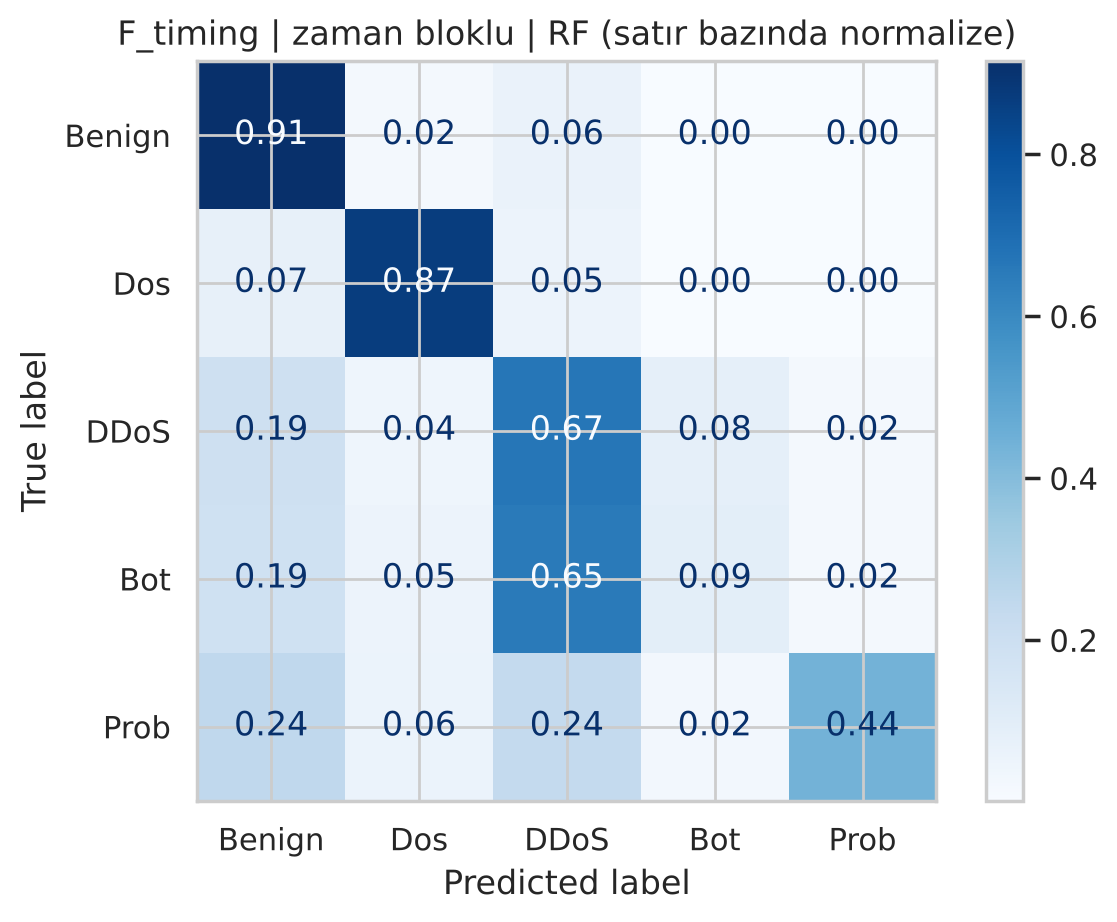

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

def quick_rf(tr, te, feats, name):
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    m.fit(tr[feats], tr['Label']); p = m.predict(te[feats])
    rep = classification_report(te['Label'], p, output_dict=True, zero_division=0)
    return {'deney': name, 'macroF1': round(f1_score(te['Label'], p, average='macro'), 3),
            **{k: round(rep[k]['recall'], 2) for k in CLASS_ORDER}}, m, p

rnd = np.random.RandomState(RANDOM_STATE).rand(len(clean)) < 0.2
rows = []
for feats, fname in [(F_FULL, 'F_full'), (F_TIMING, 'F_timing')]:
    rows.append(quick_rf(clean[~rnd], clean[rnd], feats, f'{fname} | rastgele')[0])
    r, m, p = quick_rf(train, test, feats, f'{fname} | zaman bloklu'); rows.append(r)
display(pd.DataFrame(rows).set_index('deney'))
ConfusionMatrixDisplay.from_predictions(test['Label'], p, labels=CLASS_ORDER, normalize='true', values_format='.2f', cmap='Blues')
plt.title('F_timing | zaman bloklu | RF (satır bazında normalize)'); plt.show()

**Bizim çalıştırmamızda çıkan tablo** (RF, 100 ağaç, ayarsız):

| Deney | macro F1 | Bot recall |
|---|---|---|
| F_full, rastgele bölme | 0.68 | 0.25 |
| F_full, zaman bloklu | 0.61 | 0.08 |
| F_timing, rastgele bölme | 0.67 | 0.26 |
| F_timing, zaman bloklu | 0.58 | 0.09 |

> Not: Prob kayıtları az sayıda dakikada yoğunlaştığı için test setindeki payı (%0.6) train'dekinden (%2) düşük. Prob sonuçları raporda bu notla verilmeli.

Buradan iki sonuç çıkıyor:
1. Rastgele bölme skoru **~0.08 şişiriyor**, Bot'un "başarısının" büyük kısmı sızıntıdan geliyor.
2. Byte/header özelliklerini çıkarmak sadece **~0.02** kaybettiriyor. Buna karşılık Mininet'e taşınabilir, dürüst bir model elde ediyoruz.

## 10. Temizlenmiş veriyi kaydet (modelleme notebook'u buradan devam eder)

In [17]:
keep = sorted(set(F_FULL) | set(F_TIMING)) + ['Label', 'group', 'broken']
train[keep].to_parquet('train_clean.parquet', index=False)
test[keep].to_parquet('test_clean.parquet', index=False)
pd.Series(F_TIMING).to_csv('features_timing.csv', index=False)
pd.Series(F_FULL).to_csv('features_full.csv', index=False)
print('kaydedildi')

kaydedildi


## Modelleme notebook'una (02) devredilecek kurallar
- Hiperparametre araması **sadece train** üzerinde, `StratifiedGroupKFold(groups=train['group'])` ile. Böylece CV içinde de dakika blokları bölünmez.
- SMOTE ve sınıf ağırlıkları **pipeline içinde**, sadece eğitim katlarına uygulanır (`imblearn.pipeline.Pipeline`).
- Ölçekleme (StandardScaler) sadece Lojistik Regresyon pipeline'ında. Ağaç modellerine gerek yok.
- İki aşamalı yapı: (1) Saldırı mı / Benign mi, (2) saldırıysa tür. Sonuç hem 5 sınıflı hem "birleştirilmiş" (Bot+DDoS+Prob) olarak raporlanır.
- Test seti **yalnızca bir kez**, en sonda kullanılır.
- Mininet testinde CICFlowMeter ile aynı **F_timing** sütunları üretilir. Byte sütunları modelde olmadığı için dağılım kayması riski azalır.